# SSW v1.0 — quantum generator GAN, without encoder

`z (4 random angles) → six-qubit SamplerQNN → 64 probabilities → learned decoder → x (8 features)`.
The classical discriminator sees only eight-dimensional observations. No encoder,
latent-pair discriminator, factor supervision, reconstruction loss or BiGAN objective.

The quantum circuit retains the Gaussian experiment's Hadamards, four Ry inputs,
six-repetition efficient_su2 ansatz, 84 quantum weights, Qiskit Machine Learning
and TorchConnector. The new decoder is 64→32→8 with a linear output. SSW noise
is unbounded, so there is no sigmoid, clipping or normalization of observations.
The decoder receives 64 times the probability vector as a feature scaling.
Discriminator: 8→20→1 logits; non-saturating GAN BCE, separate Adam optimizers
(lr=0.001, betas=(0.7,0.999)). The quantum sampler is unseeded, with 1024 shots.

The supplied SSW equations supersede the earlier 8×8 JEPA images. Dataset files
were recreated from that specification because the original companion code was
not found in the workspace. They are deterministic for the documented integer
selection and draw order; byte equality to an unavailable reference is not claimed.


In [1]:
import json
import sys
import subprocess
from pathlib import Path
import numpy as np
import torch

ROOT=Path.cwd()
assert (ROOT/'ssw_quantum_gan.py').is_file()
torch.set_num_threads(2)
from ssw_dataset import validate
from ssw_quantum_gan import train_run
arrays=dict(np.load(ROOT/'ssw_v1.npz',allow_pickle=False))
print(validate(arrays))
for name in ['train','val_iid','test_iid','test_ood']:
    print(name,arrays[name+'_x'].shape)
print(json.loads((ROOT/'ssw_v1_metadata.json').read_text()))

{'status': 'passed', 'checks': ['formulas', 'dtypes/shapes', 'configuration pools', 'OOD separation', 'noise statistics', 'deterministic regeneration']}
train (2000, 8)
val_iid (400, 8)
test_iid (400, 8)
test_ood (400, 8)
{'version': '1.0', 'seed': 20261011, 'noise_std': 0.05, 'split_sizes': {'train': 2000, 'val_iid': 400, 'test_iid': 400, 'test_ood': 400}, 'held_out': [[0, 0, 1, 1], [0, 1, 0, 1], [1, 0, 1, 0], [1, 1, 0, 0]], 'scaling': 'none', 'clipping': 'none', 'split_order': ['train', 'val_iid', 'test_iid', 'test_ood'], 'selection': 'rng.integers; lexicographic IID pool; listed OOD pool', 'provenance': 'Recreated from supplied specification; original companion code not found', 'validation': {'status': 'passed', 'checks': ['formulas', 'dtypes/shapes', 'configuration pools', 'OOD separation', 'noise statistics', 'deterministic regeneration']}}


## Verify before training
Check dataset equations and OOD separation, latent sensitivity, gradients,
optimizer updates and deterministic evaluation. The next cell stops on failure.

In [2]:
completed=subprocess.run([sys.executable,str(ROOT/'validate_ssw_quantum_gan.py')],
                         cwd=ROOT,capture_output=True,text=True)
print(completed.stdout)
if completed.stderr: print(completed.stderr)
completed.check_returncode()

{
  "status": "passed",
  "dataset": {
    "status": "passed",
    "checks": [
      "formulas",
      "dtypes/shapes",
      "configuration pools",
      "OOD separation",
      "noise statistics",
      "deterministic regeneration"
    ]
  },
  "input_shape": [
    2,
    4
  ],
  "output_shape": [
    2,
    8
  ],
  "encoder": false,
  "quantum_weights": 84,
  "losses": {
    "discriminator_loss": 0.6327873468399048,
    "generator_loss": 0.657378077507019,
    "discriminator_accuracy": 0.5
  },
  "checks": [
    "latent sensitivity",
    "finite input/quantum/decoder gradients",
    "generator updates",
    "D frozen during G update",
    "deterministic noiseless evaluation"
  ]
}



## Short integration baseline

Twelve optimizer steps, batch size four, sample randomly from the complete
2,000-observation training pool. This processes 48 training examples, not a full
epoch or a convergence experiment. Increase STEPS only after inspecting results.

Every four steps, evaluate the same 400 latent vectors with exact probabilities
and the learned decoder. Select checkpoints by val_iid MMD², with kernel bandwidth
determined from training data only. Test splits never select weights. The OOD
comparison is exploratory: an unconditional GAN trained on 12 configurations is
not trained to generate the four excluded configurations. No OOD success is assumed.


In [3]:
STEPS=12
BATCH_SIZE=4
OUTPUT_DIR=ROOT/'ssw_gan_results'
report=train_run(arrays,OUTPUT_DIR,steps=STEPS,batch_size=BATCH_SIZE)
print(json.dumps(report,indent=2))

Step 0/12: validation MMD²=0.48504


Training step 1/12: {'step': 1, 'discriminator_loss': 0.6333444118499756, 'generator_loss': 0.6433053612709045, 'discriminator_accuracy': 0.5}


Training step 2/12: {'step': 2, 'discriminator_loss': 0.6601885557174683, 'generator_loss': 0.6323881149291992, 'discriminator_accuracy': 0.5}


Training step 3/12: {'step': 3, 'discriminator_loss': 0.6849605441093445, 'generator_loss': 0.6359297037124634, 'discriminator_accuracy': 0.5}


Training step 4/12: {'step': 4, 'discriminator_loss': 0.6837447881698608, 'generator_loss': 0.620458722114563, 'discriminator_accuracy': 0.5}


...

Training step 10/12: {'step': 10, 'discriminator_loss': 0.6881191730499268, 'generator_loss': 0.5489414930343628, 'discriminator_accuracy': 0.5}


Training step 11/12: {'step': 11, 'discriminator_loss': 0.6844452619552612, 'generator_loss': 0.5516431927680969, 'discriminator_accuracy': 0.5}


Training step 12/12: {'step': 12, 'discriminator_loss': 0.7496660947799683, 'generator_loss': 0.5135300755500793, 'discriminator_accuracy': 0.5}


Step 12/12: validation MMD²=0.19673


{
  "dataset": "SSW v1.0",
  "encoder": false,
  "steps": 12,
  "batch_size": 4,
  "training_pool_size": 2000,
  "processed_training_examples": 48,
  "full_training_epoch": false,
  "seed": 123456,
  "best_step": 12,
  "selection": "val_iid RBF MMD\u00b2",
  "bandwidth_from_train": 2.020221659558627,
  "history": [
    {
      "step": 0,
      "rbf_mmd_squared": 0.4850379721562854,
      "feature_mean_mae": 0.5491904616355896,
      "feature_std_mae": 0.29909273982048035,
      "thresholded_configuration_counts": [
        400,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        0
      ],
      "covered_configurations": 1,
      "logic_residual_mse": 0.16540248692035675,
      "generated_min": -1.3156100511550903,
      "generated_max": 0.901003897190094
    },
    {
      "step": 4,
      "rbf_mmd_squared": 0.31129178387930945,
      "feature_mean_mae": 0.4012563228607178,
  

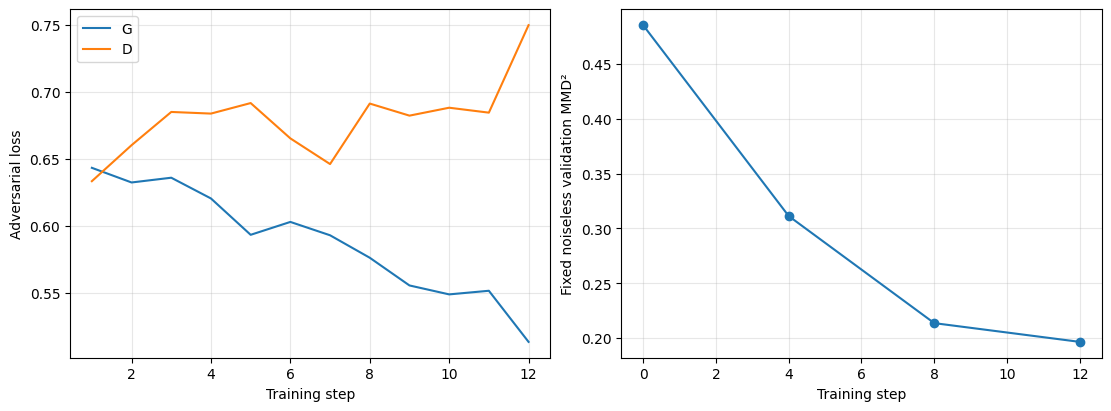

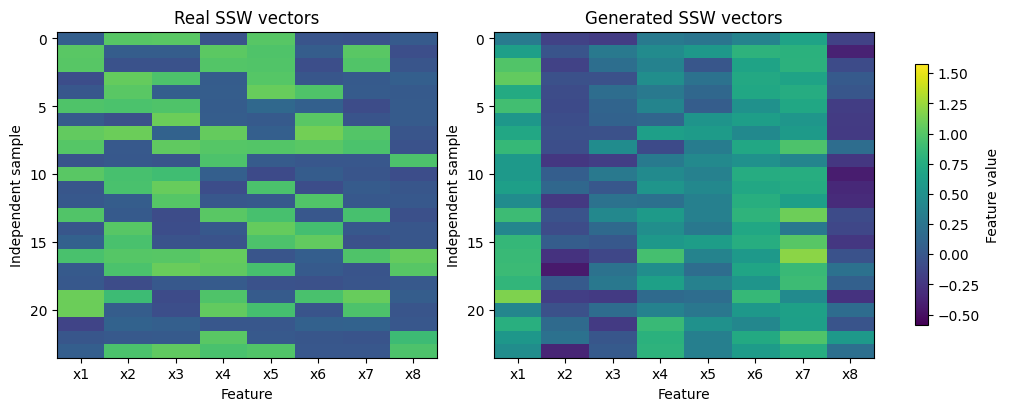

In [4]:
import matplotlib.pyplot as plt
history=report['history']
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
axes[0].plot([r['step'] for r in report['losses']],[r['generator_loss'] for r in report['losses']],label='G')
axes[0].plot([r['step'] for r in report['losses']],[r['discriminator_loss'] for r in report['losses']],label='D')
axes[0].set_ylabel('Adversarial loss'); axes[0].legend()
axes[1].plot([r['step'] for r in history],[r['rbf_mmd_squared'] for r in history],marker='o')
axes[1].set_ylabel('Fixed noiseless validation MMD²')
for ax in axes: ax.set_xlabel('Training step'); ax.grid(alpha=0.3)
fig.savefig(OUTPUT_DIR/'training.png',dpi=150,bbox_inches='tight')
plt.show()

examples=torch.load(OUTPUT_DIR/'examples.pt',weights_only=True)
fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
vmin=min(examples['validation_real'].min().item(),examples['selected_generated'].min().item())
vmax=max(examples['validation_real'].max().item(),examples['selected_generated'].max().item())
for ax,key,title in zip(axes,['validation_real','selected_generated'],['Real SSW vectors','Generated SSW vectors']):
    image=ax.imshow(examples[key][:24].numpy(),aspect='auto',vmin=vmin,vmax=vmax,cmap='viridis')
    ax.set_title(title); ax.set_xlabel('Feature'); ax.set_ylabel('Independent sample')
    ax.set_xticks(range(8),[f'x{i+1}' for i in range(8)])
fig.colorbar(image,ax=list(axes),label='Feature value',shrink=0.8)
fig.savefig(OUTPUT_DIR/'samples.png',dpi=150,bbox_inches='tight')
plt.show()

## Interpretation

These heatmaps show eight-feature vectors, not images, and displayed real and
generated samples are not paired. Configuration counts threshold the first four
generated features; the logical residual compares all eight features with the
corresponding clean world. This is a coarse diagnostic, not known generated labels.
Compare variance, coverage, logic and MMD together; low variance can indicate collapse.
Best/latest/final weights and optimizer states are saved in `ssw_gan_results`.
Unseeded measurement draws cannot be replayed exactly from saved RNG states.
The best checkpoint is checked by reloading and recomputing its validation score.
